<div align="center">

# CMPINAM — Projeto de Aprendizado de Máquina
### Classificação Binária de Renda: Adult / Census Income (`income_over_50k`)

**Instituição:** Instituto Federal de Educação, Ciência e Tecnologia de São Paulo (IFSP) — Câmpus Campinas  
**Curso:** Análise e Desenvolvimento de Sistemas  
**Professor:** Prof. Everton Meyer da Silva  
**Aluno:** Kelvin Aparecido Lima Albuquerque  
**Data:** Novembro de 2026

</div>

---

## Objetivos do Projeto

- Carregar e explorar o dataset oficial **Adult / Census Income** (`train.csv` e `test.csv`) usando **caminhos relativos** e `random_state = 42` para reprodutibilidade completa (*Run All*);
- Realizar a **Análise Exploratória de Dados (EDA)** com pelo menos 8 perguntas investigativas, múltiplos tipos de gráficos justificados, ranking preditivo e diagnósticos voltados às famílias de algoritmos;
- Implementar e comparar **9 abordagens** da disciplina (incluindo baseline e um método extra avançado não visto em aula):
  1. Baseline da Classe Majoritária;
  2. Modelo Explícito de Regras Manuais (heurística);
  3. Regressão Linear / Polinomial / Regularizada (Ridge e Lasso);
  4. Regressão Logística com **Odds Ratio** ($ODS = e^{\beta}$);
  5. Árvore de Decisão (livre vs podada);
  6. **KNN — k-Vizinhos Mais Próximos (Aula 08):** sensibilidade à escala, busca de $k$, pesos e distância;
  7. **Random Forest — Florestas Aleatórias (Aula 09):** bagging, erro Out-of-Bag (OOB) e importância Gini;
  8. **SVM — Máquinas de Vetores de Suporte (Aula 11):** margens máximas, $C$, kernel RBF e vetores de suporte;
  9. **Redes Neurais Artificiais — MLP (Aula 12):** camadas ocultas ReLU, backpropagation, inspeção de pesos e curva de perda;
  10. **Método Extra — Gradient Boosting (`HistGradientBoostingClassifier`):** aprendizado sequencial por correção de erros residuais (gradientes) baseado em histogramas;
- Avaliar os modelos estritamente no conjunto de teste oficial (`test.csv`) utilizando métricas adequadas para dados desbalanceados e interpretar os resultados no contexto do problema.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score, GridSearchCV, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, log_loss,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    mean_squared_error, r2_score
)

try:
    display
except NameError:
    display = print

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
plt.style.use('default')
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print('Bibliotecas importadas com sucesso.')

Bibliotecas importadas com sucesso.


---

## 1. Base e Preparação dos Dados

### 1.1 Origem e Descrição da Base
O dataset **Adult / Census Income** é derivado dos dados do Censo dos Estados Unidos de 1994, disponível no **UCI Machine Learning Repository**. Cada linha representa um indivíduo adulto americano com informações demográficas e socioeconômicas.

| Aspecto | Descrição |
| :--- | :--- |
| **Fonte** | UCI ML Repository — [Adult Dataset](https://archive.ics.uci.edu/dataset/2/adult) |
| **Licença** | Creative Commons Attribution 4.0 |
| **Unidade de Análise** | 1 linha = 1 indivíduo adulto dos EUA (1994) |
| **Variável-alvo** | `income_over_50k` — `0` ($\le$ US\$ 50 mil/ano) ou `1` ($>$ US\$ 50 mil/ano) |
| **Separação Oficial** | `train.csv` (32.561 linhas) e `test.csv` (16.281 linhas) — caminhos relativos |

### 1.2 Atributos Principais e Tipos
- **Numéricos contínuos/discretos (4):** `age` (idade), `capital_gain` (ganho de capital), `capital_loss` (perda de capital), `hours_per_week` (horas trabalhadas/semana).
- **Categóricos nominais/ordinais (8):** `workclass` (setor), `education` (escolaridade), `marital_status` (estado civil), `occupation` (ocupação), `relationship` (papel familiar), `race` (raça), `sex` (sexo), `native_country` (país de origem).

### 1.3 Decisões de Limpeza, Duplicatas, Dados Faltantes e Outliers
1. **Correção de Tipos:** Conversão das 8 variáveis de texto para o tipo `category` para economia de memória e tipagem semântica correta.
2. **Remoção de Duplicatas:** Identificamos e removemos **3.465 linhas duplicadas** no conjunto de treino (`train.csv` passa de 32.561 para **29.096 registros**), evitando que exemplos idênticos inflacionem métricas na validação cruzada. O conjunto de teste (`test.csv`) é mantido intacto.
3. **Tratamento de Valores Faltantes:** Existem nulos apenas em `workclass`, `occupation` e `native_country`. Para evitar vazamento de dados (*data leakage*), a imputação pela moda (`SimpleImputer(strategy='most_frequent')`) é feita **exclusivamente dentro dos pipelines de pré-processamento** ajustados sobre o treino.
4. **Tratamento de Outliers:** Variáveis financeiras como `capital_gain` possuem forte concentração em zero e valores máximos em `99.999`. **Decisão justificada:** Não removemos esses registros porque `99.999` representa um teto real de ganho de capital declarado no censo e é o indicador mais forte da classe `> 50K`. Em vez de excluir, tratamos a disparidade de escala aplicando `StandardScaler` para algoritmos sensíveis à distância/gradiente e mantendo valores brutos para modelos baseados em árvores.

In [2]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

print(f'Dimensões originais — Treino: {train_df.shape} | Teste: {test_df.shape}')

cat_cols = ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
for col in cat_cols:
    train_df[col] = train_df[col].astype('category')
    test_df[col] = test_df[col].astype('category')

dup_train = train_df.duplicated().sum()
train_df = train_df.drop_duplicates().reset_index(drop=True)
dup_test = test_df.duplicated().sum()

print(f'Duplicatas removidas no treino: {dup_train} -> Restaram {len(train_df)} registros únicos')
print(f'Duplicatas mantidas no teste (preservação da avaliação oficial): {dup_test}')

print('\nValores faltantes no TREINO:')
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])
print('\nValores faltantes no TESTE:')
print(test_df.isnull().sum()[test_df.isnull().sum() > 0])

Dimensões originais — Treino: (32561, 13) | Teste: (16281, 13)
Duplicatas removidas no treino: 3465 -> Restaram 29096 registros únicos
Duplicatas mantidas no teste (preservação da avaliação oficial): 1022

Valores faltantes no TREINO:
workclass         1632
occupation        1639
native_country     580
dtype: int64

Valores faltantes no TESTE:
workclass         963
occupation        966
native_country    274
dtype: int64


### 1.4 Distribuição das Classes (Desbalanceamento)
*Escolha do gráfico:* Utilizamos **gráfico de barras** (contagem absoluta) e **gráfico de pizza** (proporção percentual) por serem ideais para evidenciar o desbalanceamento entre as duas categorias da variável-alvo.

Classe 0 (<= 50k): 75.2% | Classe 1 (> 50k): 24.8%


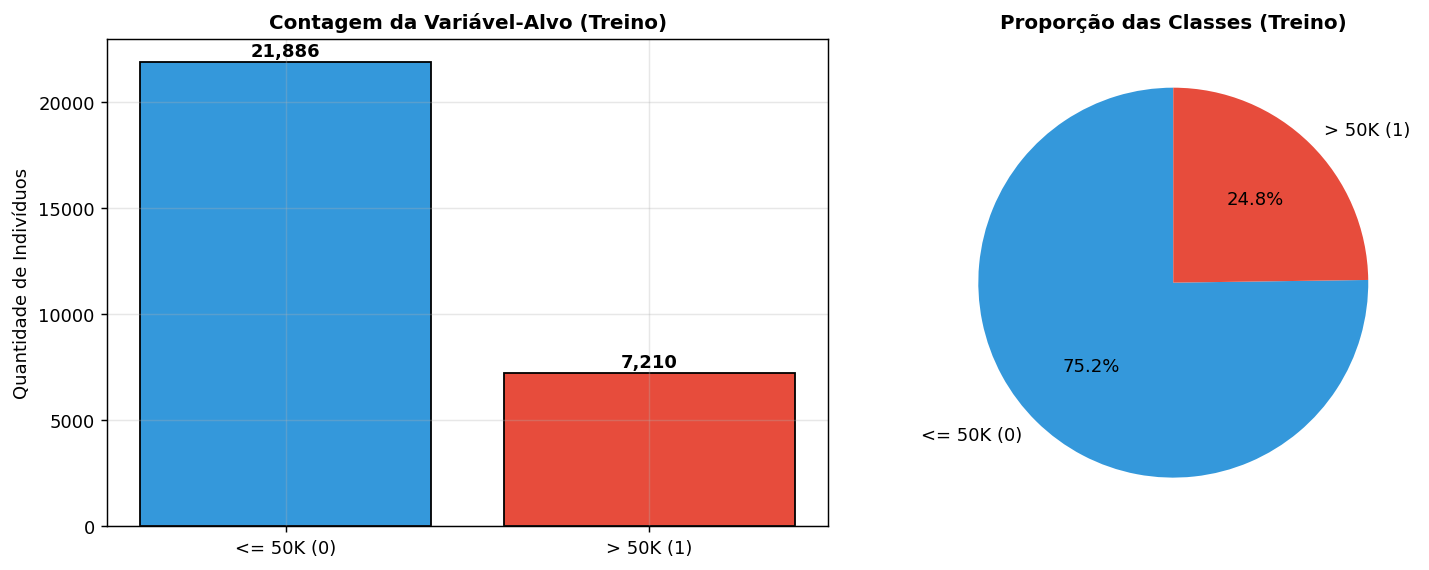

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts = train_df['income_over_50k'].value_counts()

axes[0].bar(['<= 50K (0)', '> 50K (1)'], counts.values, color=['#3498db', '#e74c3c'], edgecolor='black')
axes[0].set_title('Contagem da Variável-Alvo (Treino)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Quantidade de Indivíduos')
for idx, val in enumerate(counts.values):
    axes[0].text(idx, val + 300, f'{val:,}', ha='center', fontweight='bold')

axes[1].pie(counts.values, labels=['<= 50K (0)', '> 50K (1)'], autopct='%1.1f%%', colors=['#3498db', '#e74c3c'], startangle=90)
axes[1].set_title('Proporção das Classes (Treino)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Classe 0 (<= 50k): {counts[0]/len(train_df):.1%} | Classe 1 (> 50k): {counts[1]/len(train_df):.1%}")

---

## 2. Análise Exploratória de Dados (EDA)

Investigamos **8 perguntas fundamentais** sobre a base (incluindo relações bivariadas e multivariadas), utilizando **cinco tipos distintos de gráficos** com justificativa explícita de cada escolha:

1. **Q1:** Qual é a distribuição de idade, horas semanais e ganhos de capital? *(Histograma)*
2. **Q2:** A idade e a carga horária semanal variam conforme a faixa de renda? *(Boxplot)*
3. **Q3 (Relação):** Como o estado civil se associa à probabilidade de ganhar > US\$ 50k? *(Barras Horizontais)*
4. **Q4 (Relação):** Como a escolaridade influencia a proporção de alta renda? *(Barras Horizontais)*
5. **Q5 (Relação):** Existe diferença combinada de renda por raça e sexo? *(Barras Agrupadas)*
6. **Q6:** Qual é o comportamento da assimetria de `capital_gain` em escala logarítmica? *(Histograma Log)*
7. **Q7 (Relação):** Qual é a correlação linear entre atributos numéricos, codificados e o alvo? *(Heatmap de Correlação)*
8. **Q8 (Relação):** Quais ocupações profissionais concentram maiores proporções de renda > 50k? *(Barras Horizontais)*

In [4]:
print('=== Estatísticas Descritivas — Variáveis Numéricas ===')
display(train_df.describe().round(2))
print('\n=== Assimetria (Skewness) ===')
display(train_df[['age', 'capital_gain', 'capital_loss', 'hours_per_week']].skew().round(2))

=== Estatísticas Descritivas — Variáveis Numéricas ===

=== Assimetria (Skewness) ===


,age,capital_gain,capital_loss,hours_per_week,income_over_50k
count,29096.00,29096.00,29096.00,29096.00,29096.00
mean,39.25,1197.80,97.18,40.64,0.25
std,13.69,7778.23,424.01,12.74,0.43
min,17.00,0.00,0.00,1.00,0.00
25%,28.00,0.00,0.00,40.00,0.00
50%,38.00,0.00,0.00,40.00,0.00
75%,48.00,0.00,0.00,45.00,0.00
max,90.00,99999.00,4356.00,99.00,1.00


,0
age,0.54
capital_gain,11.33
capital_loss,4.32
hours_per_week,0.24


*Justificativa dos gráficos (Q1, Q2, Q4):* **Histogramas** revelam a distribuição contínua de frequência; **Boxplots** são ideais para comparar medianas, quartis e outliers entre grupos distintos (`<=50k` vs `>50k`); **Barras Horizontais** facilitam a leitura de rótulos categóricos ordenados.

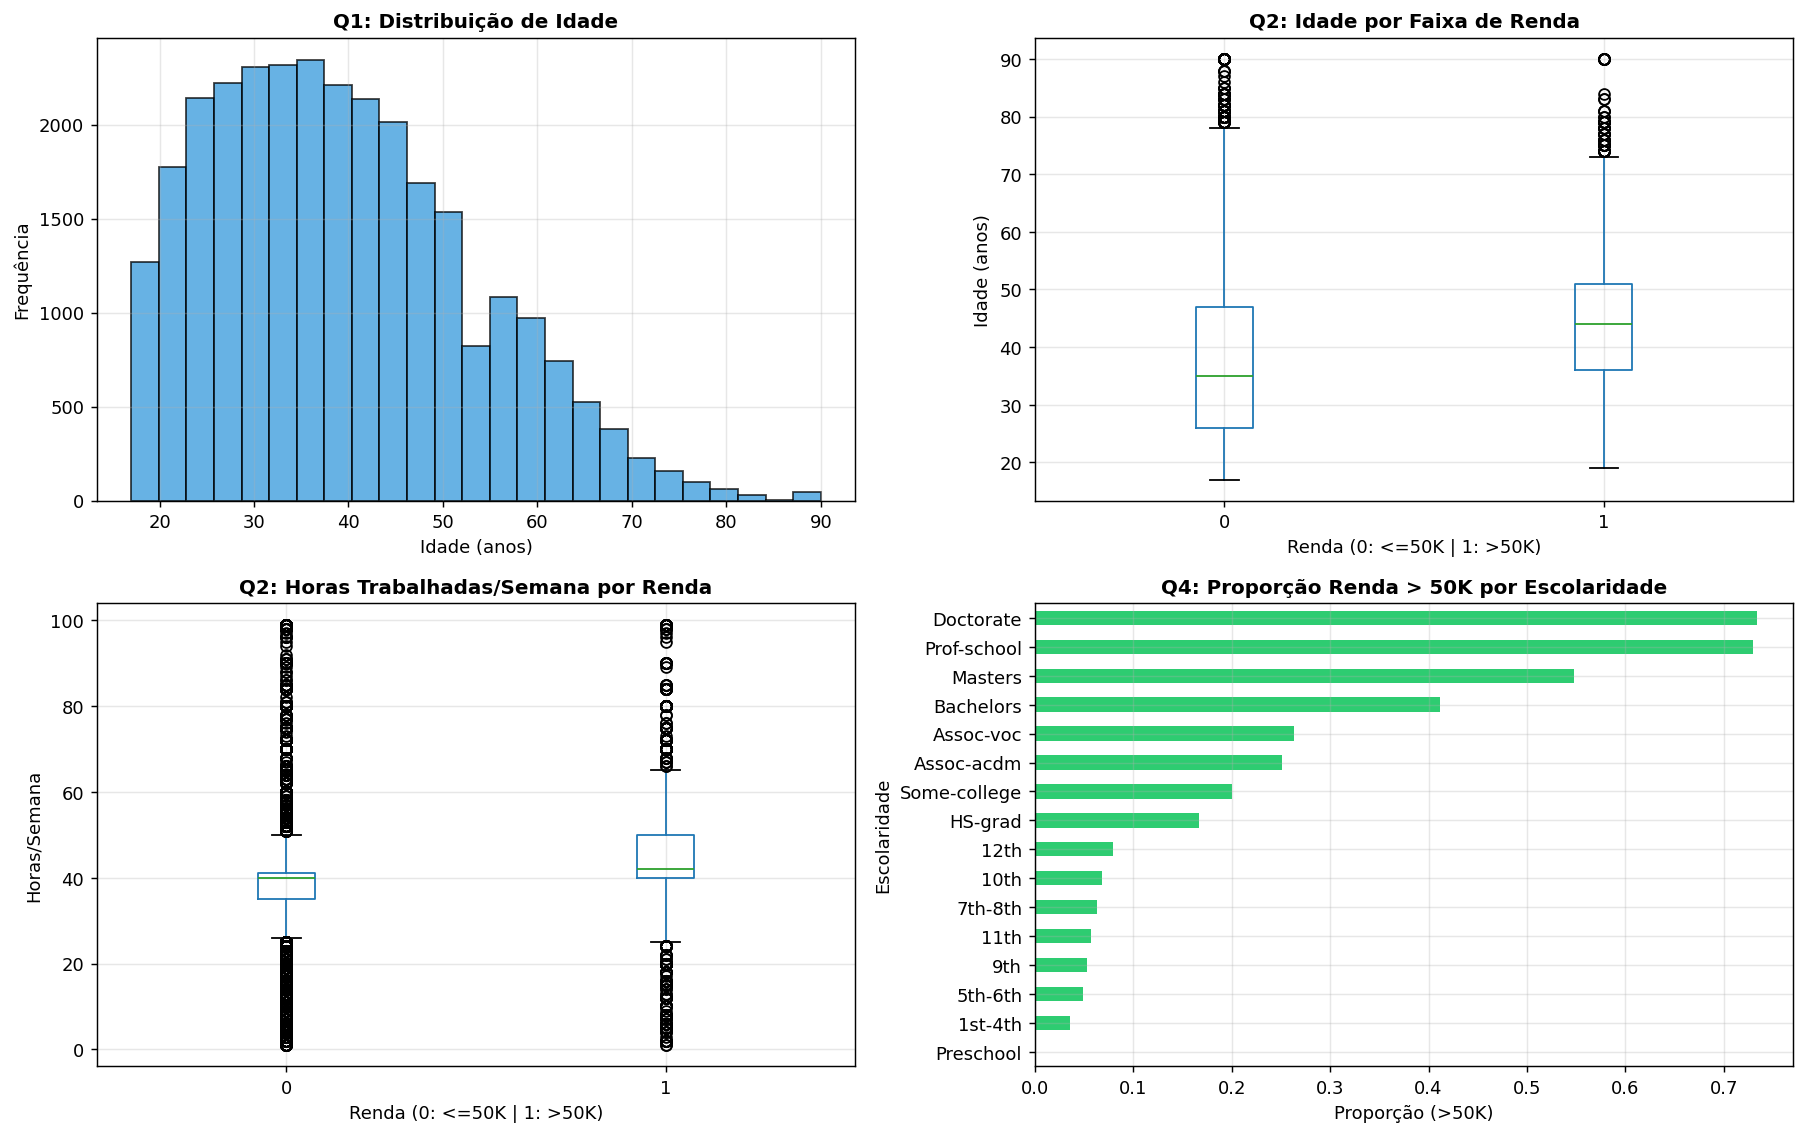

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Q1: Histograma de idade
axes[0,0].hist(train_df['age'], bins=25, color='#3498db', edgecolor='black', alpha=0.75)
axes[0,0].set_title('Q1: Distribuição de Idade', fontsize=11, fontweight='bold')
axes[0,0].set_xlabel('Idade (anos)'); axes[0,0].set_ylabel('Frequência')

# Q2: Boxplot Idade por Renda
train_df.boxplot(column='age', by='income_over_50k', ax=axes[0,1])
axes[0,1].set_title('Q2: Idade por Faixa de Renda', fontsize=11, fontweight='bold')
axes[0,1].set_xlabel('Renda (0: <=50K | 1: >50K)'); axes[0,1].set_ylabel('Idade (anos)')
plt.suptitle('')

# Q2b: Boxplot Horas/semana por Renda
train_df.boxplot(column='hours_per_week', by='income_over_50k', ax=axes[1,0])
axes[1,0].set_title('Q2: Horas Trabalhadas/Semana por Renda', fontsize=11, fontweight='bold')
axes[1,0].set_xlabel('Renda (0: <=50K | 1: >50K)'); axes[1,0].set_ylabel('Horas/Semana')
plt.suptitle('')

# Q4: Escolaridade vs Renda
taxa_ed = train_df.groupby('education', observed=False)['income_over_50k'].mean().sort_values(ascending=True)
taxa_ed.plot(kind='barh', ax=axes[1,1], color='#2ecc71')
axes[1,1].set_title('Q4: Proporção Renda > 50K por Escolaridade', fontsize=11, fontweight='bold')
axes[1,1].set_xlabel('Proporção (>50K)'); axes[1,1].set_ylabel('Escolaridade')

plt.tight_layout()
plt.show()

*Justificativa dos gráficos (Q3, Q5, Q6, Q8):* **Barras Agrupadas** permitem comparar simultaneamente duas variáveis categóricas (`race` x `sex`) em relação ao alvo; **Histograma Logarítmico** comprime ordens de grandeza para visualizar caudas pesadas em `capital_gain`.

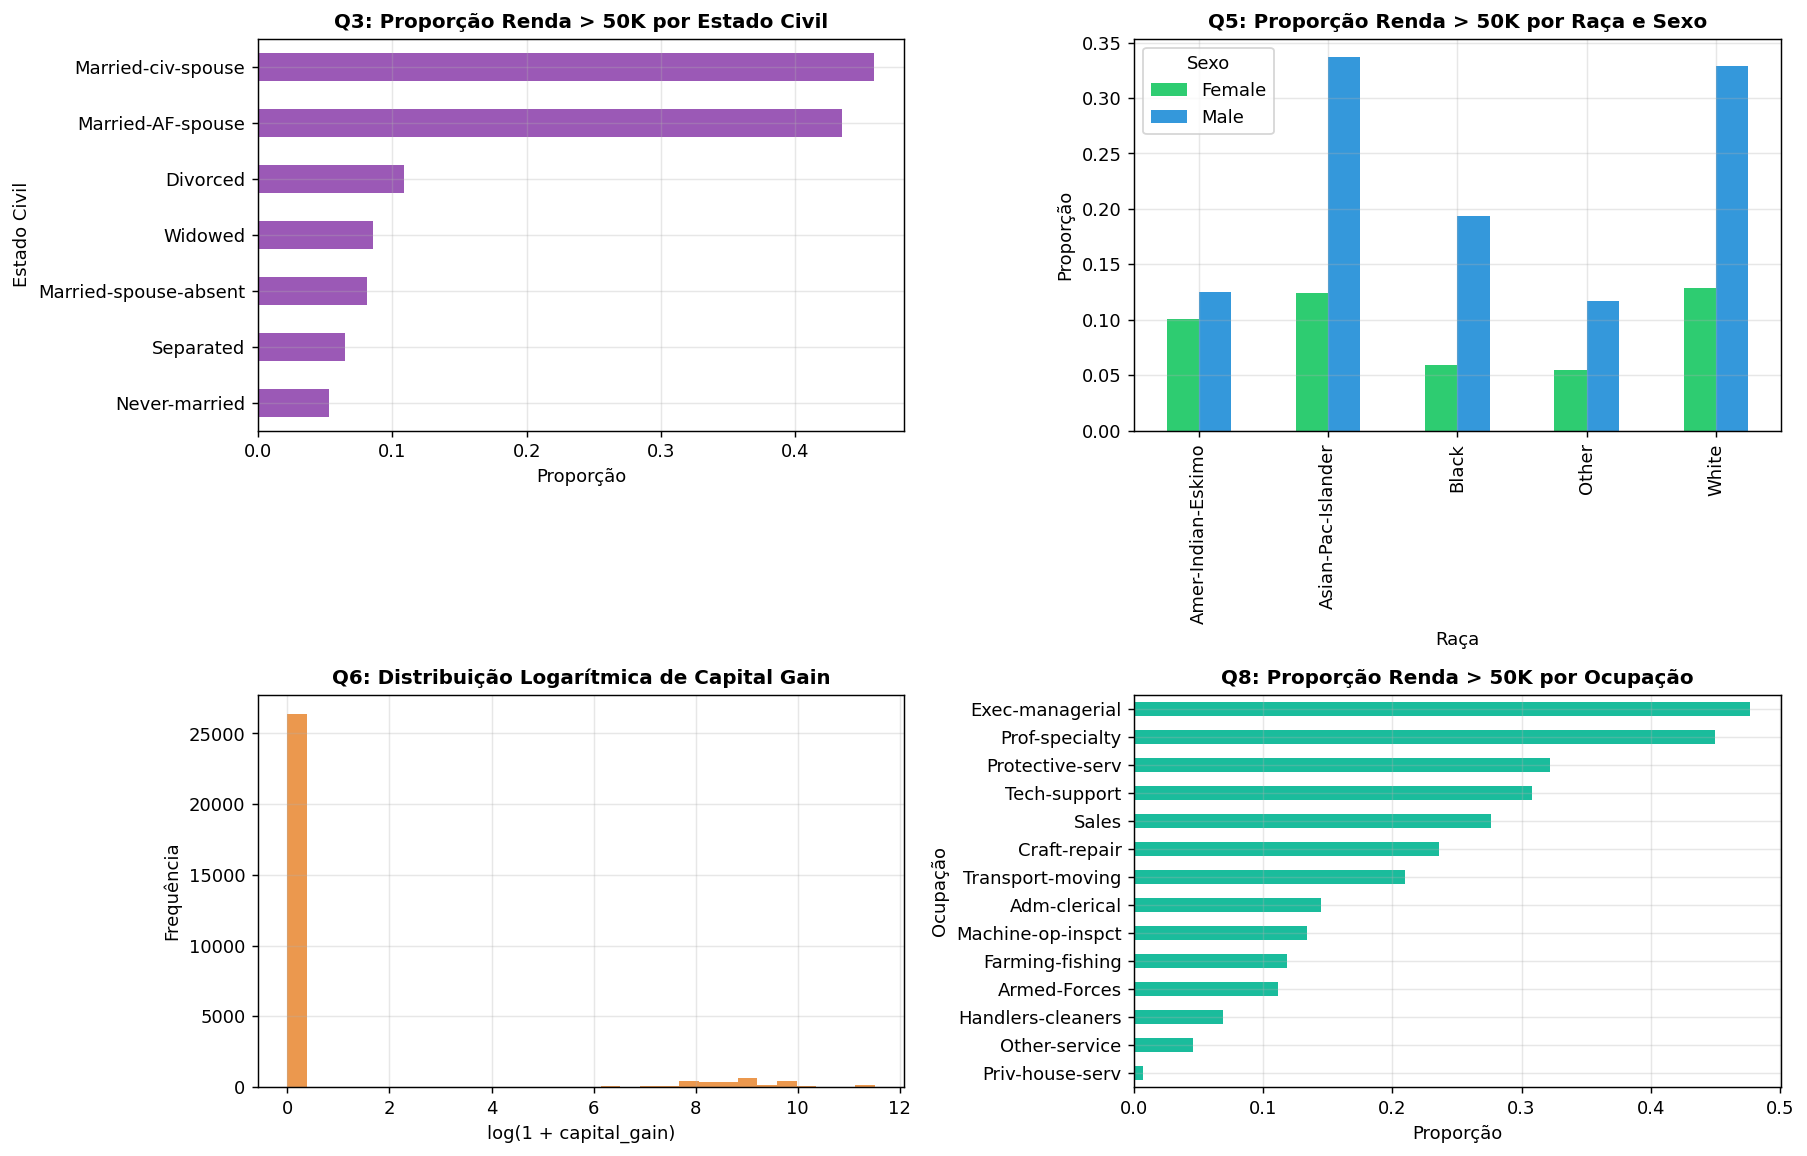

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Q3: Estado civil
taxa_m = train_df.groupby('marital_status', observed=False)['income_over_50k'].mean().sort_values(ascending=True)
taxa_m.plot(kind='barh', ax=axes[0,0], color='#9b59b6')
axes[0,0].set_title('Q3: Proporção Renda > 50K por Estado Civil', fontsize=11, fontweight='bold')
axes[0,0].set_xlabel('Proporção'); axes[0,0].set_ylabel('Estado Civil')

# Q5: Raça x Sexo
rs = train_df.groupby(['race', 'sex'], observed=False)['income_over_50k'].mean().unstack()
rs.plot(kind='bar', ax=axes[0,1], color=['#2ecc71', '#3498db'])
axes[0,1].set_title('Q5: Proporção Renda > 50K por Raça e Sexo', fontsize=11, fontweight='bold')
axes[0,1].set_xlabel('Raça'); axes[0,1].set_ylabel('Proporção')
axes[0,1].legend(title='Sexo')

# Q6: Capital gain log
axes[1,0].hist(np.log1p(train_df['capital_gain']), bins=30, color='#e67e22', alpha=0.8)
axes[1,0].set_title('Q6: Distribuição Logarítmica de Capital Gain', fontsize=11, fontweight='bold')
axes[1,0].set_xlabel('log(1 + capital_gain)'); axes[1,0].set_ylabel('Frequência')

# Q8: Ocupação
taxa_occ = train_df.groupby('occupation', observed=False)['income_over_50k'].mean().sort_values(ascending=True)
taxa_occ.plot(kind='barh', ax=axes[1,1], color='#1abc9c')
axes[1,1].set_title('Q8: Proporção Renda > 50K por Ocupação', fontsize=11, fontweight='bold')
axes[1,1].set_xlabel('Proporção'); axes[1,1].set_ylabel('Ocupação')

plt.tight_layout()
plt.show()

### 2.4 Q7 — Análise de Correlação (Heatmap)
*Justificativa do gráfico:* Um **Mapa de Calor (Heatmap)** sintetiza em uma matriz visual a intensidade e o sinal das correlações lineares entre múltiplos atributos codificados simultaneamente.

Top 10 atributos codificados mais correlacionados com o alvo:
income_over_50k                      1.0000
marital_status_Married-civ-spouse    0.4456
marital_status_Never-married         0.3064
capital_gain                         0.2307
hours_per_week                       0.2263
relationship_Own-child               0.2170
sex_Male                             0.2168
age                                  0.2153
occupation_Exec-managerial           0.2030
relationship_Not-in-family           0.1911


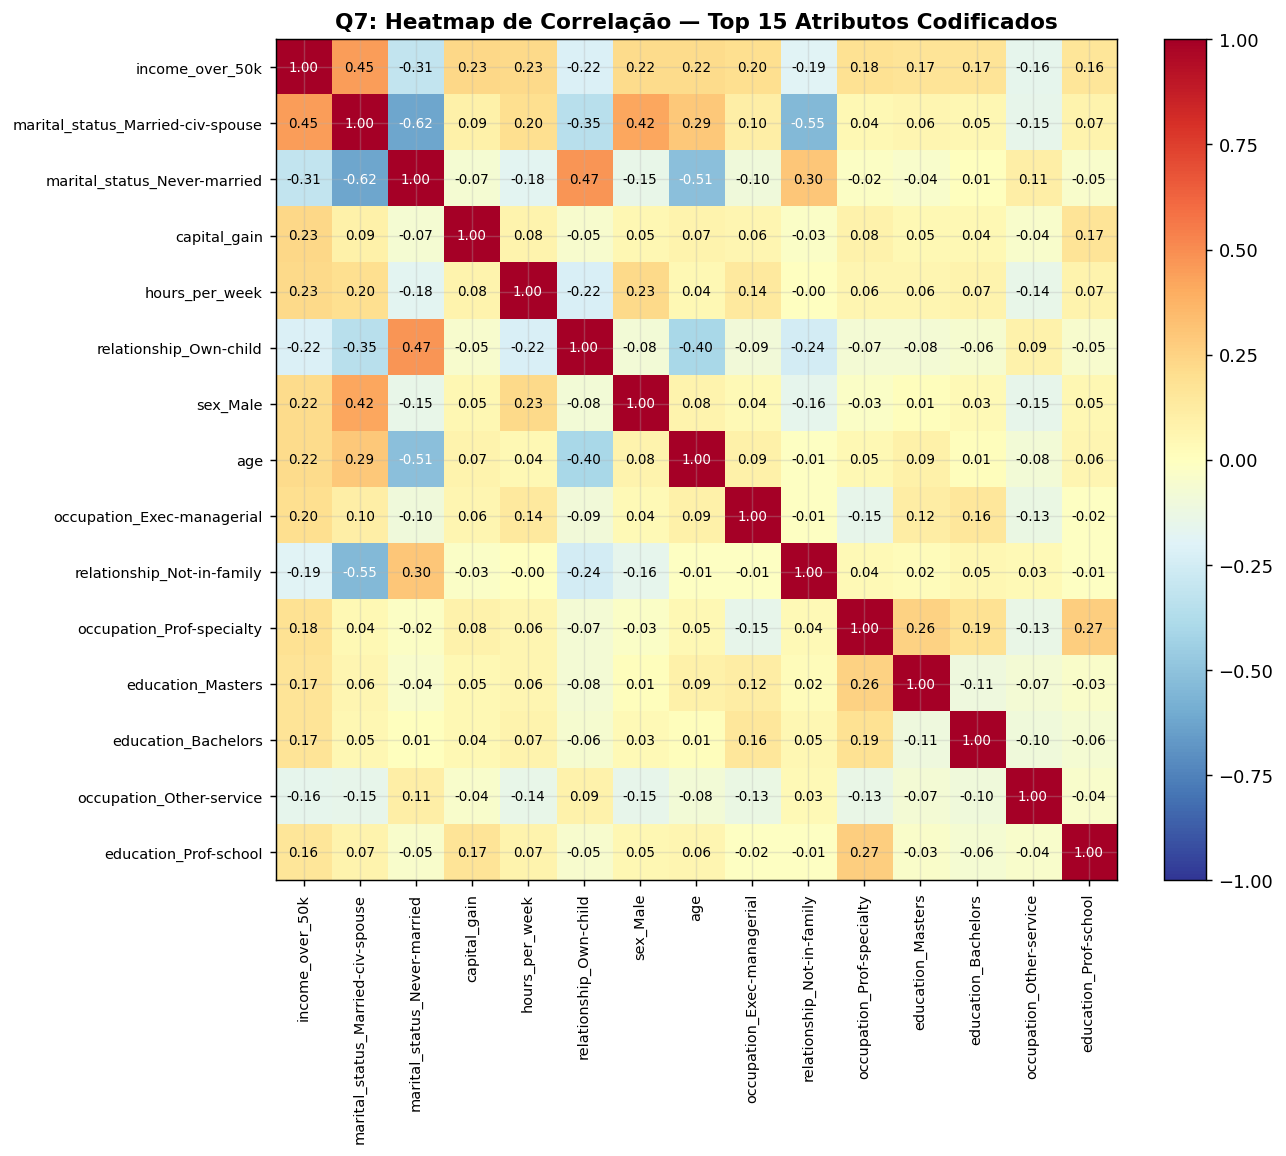

In [7]:
train_enc = pd.get_dummies(train_df, drop_first=True)
corr_all = train_enc.corr()['income_over_50k'].abs().sort_values(ascending=False)
top = corr_all.head(15)
corr_top = train_enc[list(top.index)].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_top.values, cmap='RdYlBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_top.columns)))
ax.set_yticks(range(len(corr_top.index)))
ax.set_xticklabels(corr_top.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr_top.index, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
for i in range(len(corr_top.index)):
    for j in range(len(corr_top.columns)):
        val = corr_top.iloc[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', color='white' if abs(val) > 0.5 else 'black', fontsize=7.5)
ax.set_title('Q7: Heatmap de Correlação — Top 15 Atributos Codificados', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('Top 10 atributos codificados mais correlacionados com o alvo:')
print(top.head(10).round(4).to_string())

### 2.5 Ranking Hierárquico e Seleção dos Top 8 Atributos
Calculamos o poder discriminativo individual de cada variável (correlação linear para numéricas e amplitude das taxas de alta renda para categóricas) para definir um conjunto enxuto e altamente informativo de **8 atributos** (`top_features`), reduzindo ruído e esparsidade dimensional.

In [8]:
def avaliar_corresp(df):
    res = []
    y = df['income_over_50k']
    for col in df.drop(columns=['income_over_50k']).columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            c = abs(df[col].corr(y))
            res.append({'Atributo': col, 'Tipo': 'Numérico', 'Poder Preditivo': round(c, 4), 'Detalhamento': f'Correlação linear de {c:.4f}'})
        else:
            t = df.groupby(col, observed=False)['income_over_50k'].mean()
            f = t.max() - t.min()
            res.append({'Atributo': col, 'Tipo': 'Categórico', 'Poder Preditivo': round(f, 4), 'Detalhamento': f'Taxa varia de {t.min():.1%} a {t.max():.1%}'})
    return pd.DataFrame(res).sort_values('Poder Preditivo', ascending=False).reset_index(drop=True)

df_rank = avaliar_corresp(train_df)
df_rank.index = df_rank.index + 1
display(df_rank)

# Selecionamos os 8 atributos com melhor equilíbrio entre poder preditivo, baixa cardinalidade e relevância demográfica
top_features = ['capital_gain', 'marital_status', 'relationship', 'education', 'occupation', 'hours_per_week', 'age', 'sex']
cat_features = ['marital_status', 'relationship', 'education', 'occupation', 'sex']
num_features = ['capital_gain', 'hours_per_week', 'age']

print(f'Top 8 Atributos Selecionados: {top_features}')
print(f'  Categóricos ({len(cat_features)}): {cat_features}')
print(f'  Numéricos ({len(num_features)}):   {num_features}')

Top 8 Atributos Selecionados: ['capital_gain', 'marital_status', 'relationship', 'education', 'occupation', 'hours_per_week', 'age', 'sex']
  Categóricos (5): ['marital_status', 'relationship', 'education', 'occupation', 'sex']
  Numéricos (3):   ['capital_gain', 'hours_per_week', 'age']


,Atributo,Tipo,Poder Preditivo,Detalhamento
1,education,Categórico,0.7338,Taxa varia de 0.0% a 73.4%
2,workclass,Categórico,0.5545,Taxa varia de 0.0% a 55.5%
3,occupation,Categórico,0.4699,Taxa varia de 0.7% a 47.7%
4,relationship,Categórico,0.4548,Taxa varia de 1.6% a 47.1%
5,native_country,Categórico,0.4186,Taxa varia de 0.0% a 41.9%
6,marital_status,Categórico,0.4054,Taxa varia de 5.3% a 45.8%
7,capital_gain,Numérico,0.2307,Correlação linear de 0.2307
8,hours_per_week,Numérico,0.2263,Correlação linear de 0.2263
9,age,Numérico,0.2153,Correlação linear de 0.2153
10,sex,Categórico,0.1978,Taxa varia de 11.7% a 31.5%


### 2.6 EDA Orientada aos Algoritmos (KNN, Random Forest, SVM e Redes Neurais MLP)

#### 2.6.1 Efeito da Escala e Dispersão nas Distâncias e Gradientes
- **KNN (Aula 08) & SVM (Aula 11):** Calculam distâncias euclidianas ($d(x,z) = \sqrt{\sum (x_i - z_i)^2}$) e normas quadráticas ($\|x-z\|^2$).
- **Redes Neurais MLP (Aula 12):** Atualizam pesos via gradiente descendente ($w \leftarrow w - \eta \nabla L$), multiplicando diretamente os valores de entrada $x_i$.
- **Random Forest (Aula 09) & Gradient Boosting:** São **invariantes a transformações monotônicas de escala**, pois dividem os dados por ordenação ($x_j \le c$).

Demonstramos abaixo como `capital_gain` (de 0 a 99.999) domina **> 99,9%** da distância euclidiana sem padronização:

In [9]:
desc_scale = train_df[['capital_gain', 'hours_per_week', 'age']].describe().T[['min', 'mean', 'std', 'max']]
desc_scale['amplitude'] = desc_scale['max'] - desc_scale['min']
display(desc_scale.round(2))

# Exemplo numérico prático de distâncias com vs sem StandardScaler
scaler_demo = StandardScaler().fit(train_df[['age', 'hours_per_week', 'capital_gain']])
q = np.array([[39, 40, 2174]])
a = np.array([[50, 13, 0]])
b = np.array([[31, 50, 14084]])

d_qa_raw = np.linalg.norm(q - a)
d_qb_raw = np.linalg.norm(q - b)
q_sc, a_sc, b_sc = scaler_demo.transform(q), scaler_demo.transform(a), scaler_demo.transform(b)
d_qa_sc = np.linalg.norm(q_sc - a_sc)
d_qb_sc = np.linalg.norm(q_sc - b_sc)

print(f'Distância SEM escala: d(Q, A) = {d_qa_raw:.2f} | d(Q, B) = {d_qb_raw:.2f} -> Mais próximo: {"A" if d_qa_raw < d_qb_raw else "B"}')
print(f'Distância COM escala: d(Q, A) = {d_qa_sc:.2f} | d(Q, B) = {d_qb_sc:.2f} -> Mais próximo: {"A" if d_qa_sc < d_qb_sc else "B"}')

Distância SEM escala: d(Q, A) = 2174.20 | d(Q, B) = 11910.01 -> Mais próximo: A
Distância COM escala: d(Q, A) = 2.28 | d(Q, B) = 1.82 -> Mais próximo: B


,min,mean,std,max,amplitude
capital_gain,0.0,1197.80,7778.23,99999.0,99999.0
hours_per_week,1.0,40.64,12.74,99.0,98.0
age,17.0,39.25,13.69,90.0,73.0


#### 2.6.2 Sobreposição de Classes e Fronteiras Não Lineares
*Justificativa do gráfico:* **Gráficos de dispersão (scatter plot)** permitem observar diretamente no plano 2D a mistura entre as classes e justificar por que fronteiras lineares simples não atingem separação perfeita.

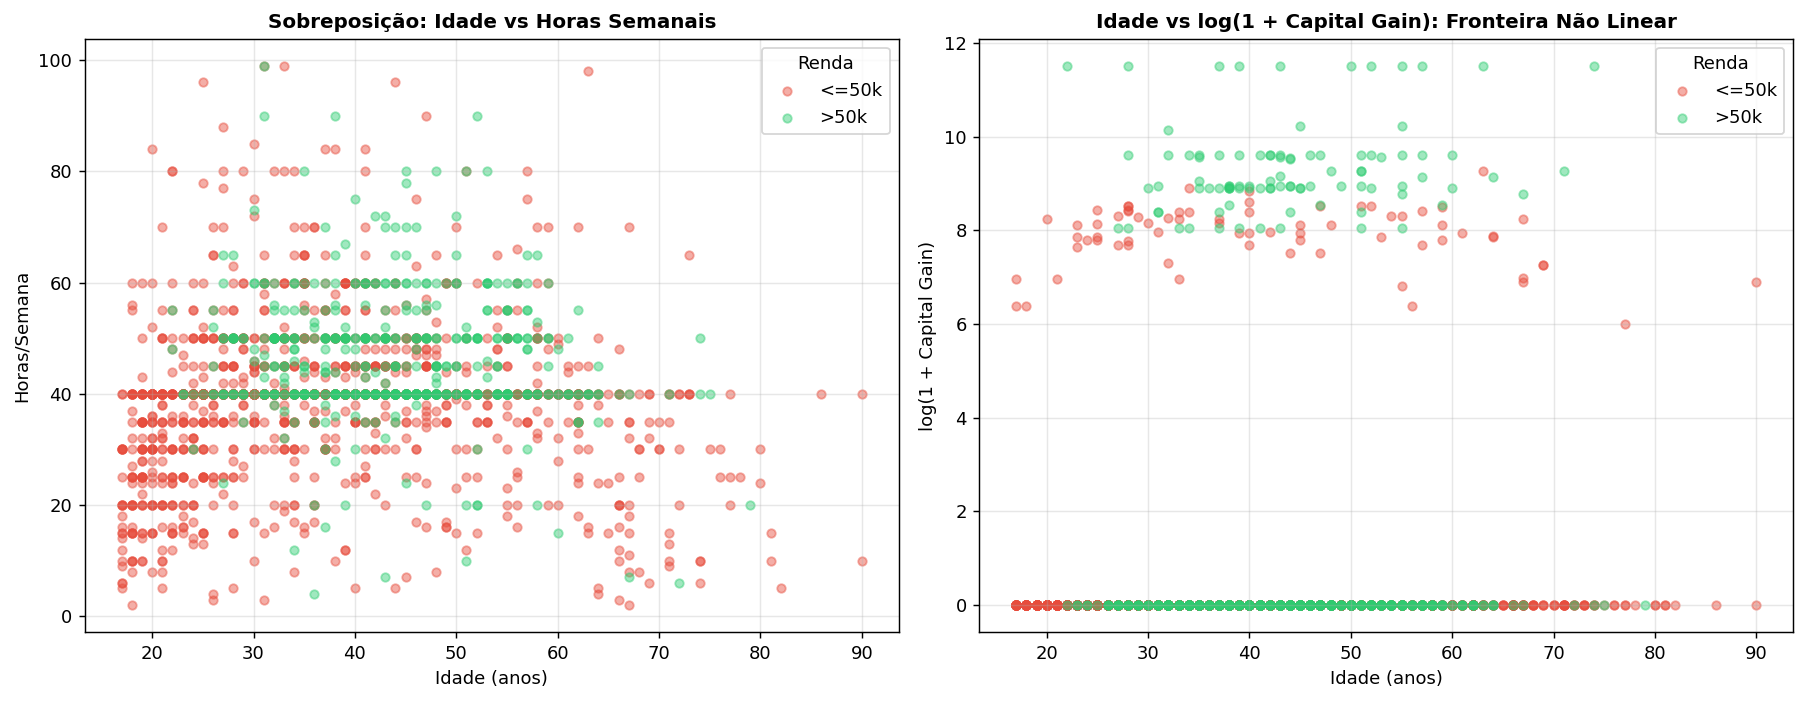

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
amostra_plot = train_df.sample(n=2000, random_state=RANDOM_STATE)
m0 = amostra_plot['income_over_50k'] == 0
m1 = amostra_plot['income_over_50k'] == 1

axes[0].scatter(amostra_plot.loc[m0, 'age'], amostra_plot.loc[m0, 'hours_per_week'], c='#e74c3c', label='<=50k', alpha=0.45, s=22)
axes[0].scatter(amostra_plot.loc[m1, 'age'], amostra_plot.loc[m1, 'hours_per_week'], c='#2ecc71', label='>50k', alpha=0.45, s=22)
axes[0].set_title('Sobreposição: Idade vs Horas Semanais', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Idade (anos)'); axes[0].set_ylabel('Horas/Semana'); axes[0].legend(title='Renda')

amostra_plot['cap_gain_log'] = np.log1p(amostra_plot['capital_gain'])
axes[1].scatter(amostra_plot.loc[m0, 'age'], amostra_plot.loc[m0, 'cap_gain_log'], c='#e74c3c', label='<=50k', alpha=0.45, s=22)
axes[1].scatter(amostra_plot.loc[m1, 'age'], amostra_plot.loc[m1, 'cap_gain_log'], c='#2ecc71', label='>50k', alpha=0.45, s=22)
axes[1].set_title('Idade vs log(1 + Capital Gain): Fronteira Não Linear', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Idade (anos)'); axes[1].set_ylabel('log(1 + Capital Gain)'); axes[1].legend(title='Renda')

plt.tight_layout()
plt.show()

### 2.7 Síntese dos Achados e Limitações da Base
- **Achados Principais:** Indivíduos casados (`Married-civ-spouse`), com ensino superior (`Bachelors`, `Masters`, `Doctorate`), ocupações executivas/especializadas, idade entre 35–55 anos, carga horária acima de 40h/semana e ganhos de capital positivos têm probabilidade drasticamente maior de ganhar > US\$ 50k.
- **Implicações para Modelagem:** A sobreposição na região central (30–50 anos, 40h/semana) exige modelos capazes de aprender interações não lineares (Árvores, Random Forest, MLP, Gradient Boosting) e margem flexível (SVM).
- **Limitações da Base:**
  1. **Defasagem Histórica (1994):** Valores monetários (limiar de 50k) e estrutura salarial não refletem a economia atual.
  2. **Viés Estrutural:** Atributos sensíveis como `sex` e `race` apresentam disparidades históricas nos dados (ex.: homens e pessoas brancas/asiáticas com taxas maiores na época), o que exige cuidado ético para não perpetuar desigualdades em aplicações reais.
  3. **Desbalanceamento (75%/25%):** Acurácia isolada pode mascarar erros na classe minoritária, exigindo Precisão, Recall, F1-Score, ROC-AUC e PR-AUC.

---

## 3. Modelo Explícito de Regras (Heurística Baseada na EDA)

Construímos um classificador explícito puramente baseado em regras de negócio descobertas na EDA, servindo como referência interpretável antes dos modelos estatísticos e de aprendizado de máquina.

In [11]:
class ModeloExplicito:
    def predict_single(self, r):
        if r['capital_gain'] > 5000:
            return 1
        elif r['education'] in ['Bachelors', 'Masters', 'Doctorate', 'Prof-school'] and r['hours_per_week'] >= 40:
            return 1
        elif r['age'] >= 30 and r['hours_per_week'] >= 40 and r['marital_status'] == 'Married-civ-spouse':
            return 1
        return 0
    def predict(self, df):
        return df.apply(self.predict_single, axis=1).values

modelo_exp = ModeloExplicito()
y_test = test_df['income_over_50k'].values
y_pred_exp = modelo_exp.predict(test_df)

print('=== Avaliação do Modelo Explícito no Teste ===')
print(f'Acurácia: {accuracy_score(y_test, y_pred_exp):.3f}')
print(f'Precisão: {precision_score(y_test, y_pred_exp):.3f}')
print(f'Recall:   {recall_score(y_test, y_pred_exp):.3f}')
print(f'F1-Score: {f1_score(y_test, y_pred_exp):.3f}')

=== Avaliação do Modelo Explícito no Teste ===
Acurácia: 0.720
Precisão: 0.452
Recall:   0.867
F1-Score: 0.594


---

## 4. Pré-processamento Seletivo, Prevenção de Vazamento e Validação

- **Separação Treino/Teste:** `train.csv` e `test.csv` vêm separados desde a origem; **nenhum transformador (`SimpleImputer`, `OneHotEncoder`, `StandardScaler`) toca em `test.csv` durante o ajuste (`fit`)**.
- **Transformações Aplicadas:**
  - Categóricas: `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
  - Numéricas: `preproc_scaled` aplica `StandardScaler()` (para Regressão Logística, KNN, SVM e MLP); `preproc_unscaled` mantém `'passthrough'` (para Árvore de Decisão, Random Forest e Gradient Boosting).
- **Estratégia de Validação:** Validação Cruzada Estratificada (`StratifiedKFold`, $k=5$ e $k=3$ para buscas pesadas) mantendo a proporção exata das classes em cada dobra.
- **Justificativa das Métricas:** Como 76,4% do teste pertence à classe 0, um modelo trivial acerta 76,4% prevendo sempre zero. Portanto, avaliamos **Precisão, Recall, F1-Score (equilíbrio na classe `>50k`), ROC-AUC e PR-AUC**.

In [12]:
X_train = train_df[top_features].copy()
y_train = train_df['income_over_50k'].copy()
X_test = test_df[top_features].copy()
y_test = test_df['income_over_50k'].copy()

cat_tf = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preproc_scaled = ColumnTransformer([
    ('cat', cat_tf, cat_features),
    ('num', StandardScaler(), num_features)
])

preproc_unscaled = ColumnTransformer([
    ('cat', cat_tf, cat_features),
    ('num', 'passthrough', num_features)
])

X_train_proc = preproc_scaled.fit_transform(X_train)
X_test_proc = preproc_scaled.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=10000, stratify=y_train, random_state=RANDOM_STATE)

print(f'Pré-processamento ajustado exclusivamente no treino:')
print(f'  X_train_proc: {X_train_proc.shape} | X_test_proc: {X_test_proc.shape}')

Pré-processamento ajustado exclusivamente no treino:
  X_train_proc: (29096, 48) | X_test_proc: (16281, 48)


---

## 5. Regressão Linear — Simples, Múltipla, Polinomial e Regularização

Ajustamos modelos de regressão linear para verificar a capacidade (e as limitações) de uma aproximação linear contínua para prever um alvo binário.

In [13]:
# 1. Regressão Linear Simples (age)
lr_simples = LinearRegression().fit(train_df[['age']], y_train)
y_pred_simples = lr_simples.predict(test_df[['age']])
print('=== Regressão Linear Simples (age) ===')
print(f'Beta 1: {lr_simples.coef_[0]:.4f} | Beta 0: {lr_simples.intercept_:.4f}')
print(f'R² no Teste: {r2_score(y_test, y_pred_simples):.4f} | MSE: {mean_squared_error(y_test, y_pred_simples):.4f}')

# 2. Regressão Linear Múltipla
lr_multipla = LinearRegression().fit(X_train_proc, y_train)
print(f'\n=== Regressão Linear Múltipla ===')
print(f'R² no Teste: {r2_score(y_test, lr_multipla.predict(X_test_proc)):.4f}')

# 3. Polinomial (Grau 2) e Regularização (Ridge / Lasso)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly_tr = poly.fit_transform(train_df[num_features])
X_poly_te = poly.transform(test_df[num_features])
lr_poly = LinearRegression().fit(X_poly_tr, y_train)

ridge = Ridge(alpha=1.0, random_state=RANDOM_STATE).fit(X_train_proc, y_train)
lasso = Lasso(alpha=0.01, random_state=RANDOM_STATE).fit(X_train_proc, y_train)

print(f'\n=== Polinomial e Regularização ===')
print(f'R² Polinomial (Grau 2 - numéricas): {r2_score(y_test, lr_poly.predict(X_poly_te)):.4f}')
print(f'R² Ridge (L2): {r2_score(y_test, ridge.predict(X_test_proc)):.4f}')
print(f'R² Lasso (L1): {r2_score(y_test, lasso.predict(X_test_proc)):.4f} (atributos zerados: {np.sum(lasso.coef_ == 0)} de {len(lasso.coef_)})')

=== Regressão Linear Simples (age) ===
Beta 1: 0.0068 | Beta 0: -0.0187
R² no Teste: 0.0495 | MSE: 0.1715

=== Regressão Linear Múltipla ===
R² no Teste: 0.3472

=== Polinomial e Regularização ===
R² Polinomial (Grau 2 - numéricas): 0.1692
R² Ridge (L2): 0.3472
R² Lasso (L1): 0.2936 (atributos zerados: 39 de 48)


---

## 6. Regressão Logística (Aula 06) e Árvore de Decisão (Aula 07)

Aplicamos `GridSearchCV` com validação cruzada estratificada (5 folds) otimizando o `F1-Score`. Na Regressão Logística utilizamos `class_weight='balanced'` para compensar o desbalanceamento das classes e extraímos os **Odds Ratios** ($ODS = e^\beta$) para interpretabilidade.

In [14]:
log_model = Pipeline([('preprocessor', preproc_scaled), ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'))])
tree_model = Pipeline([('preprocessor', preproc_unscaled), ('classifier', DecisionTreeClassifier(random_state=RANDOM_STATE))])

baseline_val = y_train.value_counts(normalize=True).max()
log_cv = cross_val_score(log_model, X_train, y_train, cv=cv, scoring='f1')
tree_cv = cross_val_score(tree_model, X_train, y_train, cv=cv, scoring='f1')

print(f'Baseline Majoritário (classe 0): {baseline_val:.3f}')
print(f'F1 CV Inicial — Regressão Logística: {log_cv.mean():.3f} ± {log_cv.std():.3f}')
print(f'F1 CV Inicial — Árvore de Decisão:   {tree_cv.mean():.3f} ± {tree_cv.std():.3f}')

grid_log = GridSearchCV(log_model, {'classifier__C': [0.1, 1, 10]}, cv=cv, scoring='f1', n_jobs=-1).fit(X_train, y_train)
grid_tree = GridSearchCV(tree_model, {'classifier__max_depth': [5, 7, 10], 'classifier__min_samples_leaf': [2, 5]}, cv=cv, scoring='f1', n_jobs=-1).fit(X_train, y_train)

best_log = grid_log.best_estimator_
best_tree = grid_tree.best_estimator_

print(f'\nMelhor LogReg: {grid_log.best_params_} | F1 CV: {grid_log.best_score_:.3f}')
print(f'Melhor Árvore: {grid_tree.best_params_} | F1 CV: {grid_tree.best_score_:.3f}')

Baseline Majoritário (classe 0): 0.752
F1 CV Inicial — Regressão Logística: 0.678 ± 0.008
F1 CV Inicial — Árvore de Decisão:   0.573 ± 0.008

Melhor LogReg: {'classifier__C': 10} | F1 CV: 0.679
Melhor Árvore: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2} | F1 CV: 0.638


### 6.1 Interpretabilidade via Odds Ratio ($ODS = e^\beta$) na Regressão Logística
O Odds Ratio mede o impacto multiplicativo de cada característica sobre a chance de renda $>$ US\$ 50k ($ODS > 1$ aumenta a chance; $ODS < 1$ reduz).

In [15]:
fnames = best_log.named_steps['preprocessor'].get_feature_names_out()
coefs = best_log.named_steps['classifier'].coef_[0]
df_ods = pd.DataFrame({'Atributo': fnames, 'Coef (Beta)': coefs.round(4), 'ODS': np.exp(coefs).round(4)}).sort_values('ODS', ascending=False)

print('=== TOP 5 Fatores que MAIS AUMENTAM a chance de Renda > 50K ===')
display(df_ods.head(5))
print('=== TOP 5 Fatores que MAIS REDUZEM a chance ===')
display(df_ods.tail(5))

=== TOP 5 Fatores que MAIS AUMENTAM a chance de Renda > 50K ===
=== TOP 5 Fatores que MAIS REDUZEM a chance ===


,Atributo,Coef (Beta),ODS
23,cat__education_Doctorate,2.5860,13.2771
27,cat__education_Prof-school,2.3461,10.4449
45,num__capital_gain,2.3282,10.2593
1,cat__marital_status_Married-AF-spouse,2.0035,7.4153
25,cat__education_Masters,1.6966,5.4556


,Atributo,Coef (Beta),ODS
18,cat__education_7th-8th,-1.2394,0.2895
17,cat__education_5th-6th,-1.3239,0.2661
16,cat__education_1st-4th,-1.5629,0.2095
37,cat__occupation_Priv-house-serv,-3.7097,0.0245
26,cat__education_Preschool,-4.1712,0.0154


---

## 7. Modelagem com KNN — k-Vizinhos Mais Próximos (Aula 08)

Testamos o impacto da padronização (`StandardScaler`), realizamos busca em grade (`n_neighbors`, `weights`, `p`) e plotamos a curva de $F_1 \times k$ para visualizar o ponto de cotovelo e o equilíbrio viés-variância.

=== Comparação KNN sem vs com escala (k = 15) ===
F1 médio SEM escala: 0.6252 ± 0.0089
F1 médio COM escala: 0.6258 ± 0.0031

Melhor KNN: {'clf__n_neighbors': 11, 'clf__p': 2, 'clf__weights': 'uniform'} | F1 CV: 0.6262


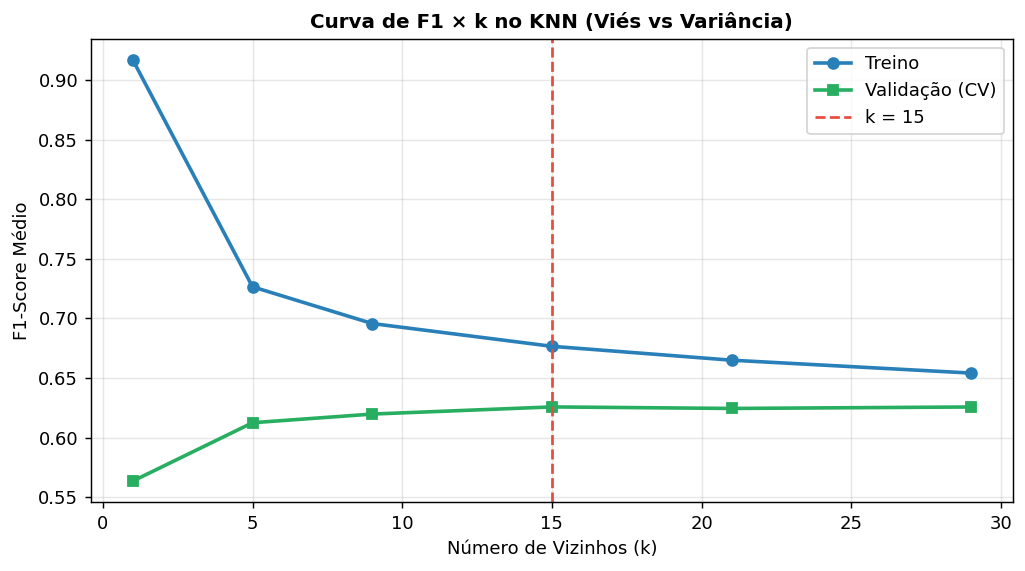

In [16]:
knn_sem = Pipeline([('prep', preproc_unscaled), ('clf', KNeighborsClassifier(n_neighbors=15, n_jobs=-1))])
knn_com = Pipeline([('prep', preproc_scaled), ('clf', KNeighborsClassifier(n_neighbors=15, n_jobs=-1))])

f1_sem = cross_val_score(knn_sem, X_train, y_train, cv=cv3, scoring='f1')
f1_com = cross_val_score(knn_com, X_train, y_train, cv=cv3, scoring='f1')
print('=== Comparação KNN sem vs com escala (k = 15) ===')
print(f'F1 médio SEM escala: {f1_sem.mean():.4f} ± {f1_sem.std():.4f}')
print(f'F1 médio COM escala: {f1_com.mean():.4f} ± {f1_com.std():.4f}')

param_grid_knn = {
    'clf__n_neighbors': [5, 11, 15, 21],
    'clf__weights': ['uniform', 'distance'],
    'clf__p': [1, 2]
}
grid_knn = GridSearchCV(knn_com, param_grid_knn, cv=cv3, scoring='f1', n_jobs=-1).fit(X_train, y_train)
best_knn = grid_knn.best_estimator_
print(f'\nMelhor KNN: {grid_knn.best_params_} | F1 CV: {grid_knn.best_score_:.4f}')

# Curva de k (treino vs validação)
k_list = [1, 5, 9, 15, 21, 29]
tr_k, te_k = [], []
for kv in k_list:
    r = cross_validate(Pipeline([('prep', preproc_scaled), ('clf', KNeighborsClassifier(n_neighbors=kv, n_jobs=-1))]),
                       X_train, y_train, cv=cv3, scoring='f1', return_train_score=True)
    tr_k.append(r['train_score'].mean())
    te_k.append(r['test_score'].mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_list, tr_k, marker='o', label='Treino', color='#2980b9', lw=2)
ax.plot(k_list, te_k, marker='s', label='Validação (CV)', color='#27ae60', lw=2)
ax.axvline(x=15, color='#e74c3c', linestyle='--', label='k = 15')
ax.set_title('Curva de F1 × k no KNN (Viés vs Variância)', fontsize=11, fontweight='bold')
ax.set_xlabel('Número de Vizinhos (k)'); ax.set_ylabel('F1-Score Médio')
ax.legend(); plt.tight_layout(); plt.show()

---

## 8. Modelagem com Random Forest — Florestas Aleatórias (Aula 09)

A **Random Forest** combina 150 árvores descorrelacionadas treinadas por *bagging* (sorteio bootstrap) com sorteio de atributos (`max_features='sqrt'`). Avaliamos o **Erro Out-of-Bag (OOB)** sem tocar no teste e extraímos o ranking de importância dos atributos por redução de impureza Gini.

Acurácia Out-of-Bag (OOB): 0.8477 | Erro OOB: 0.1523
Melhor Random Forest: {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 150} | F1 CV: 0.6588


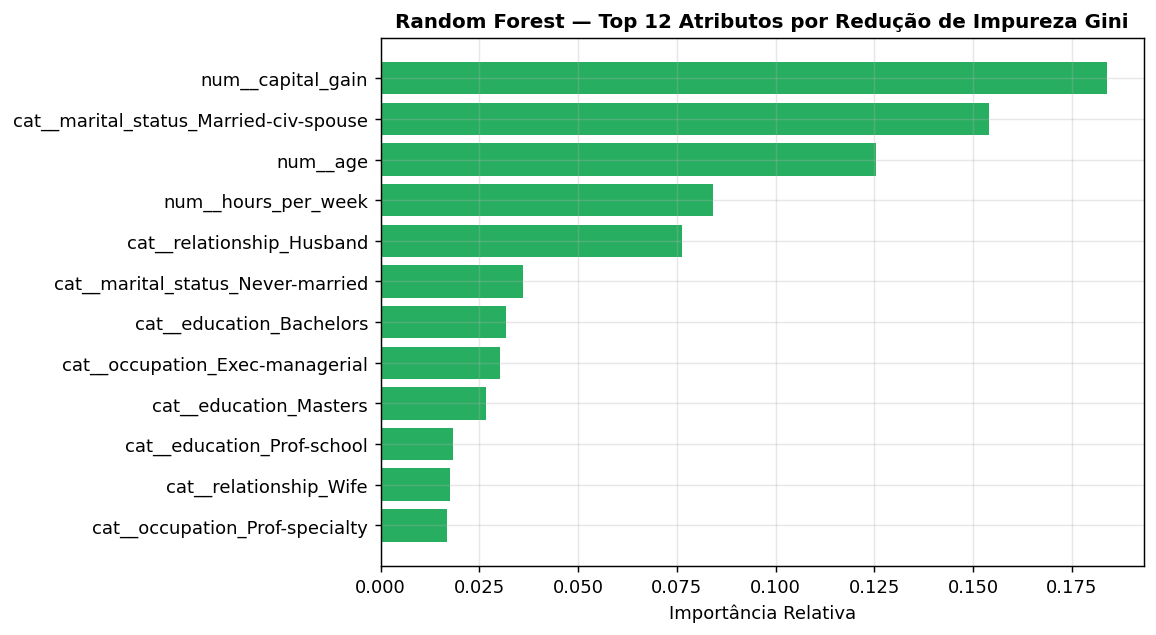

In [17]:
rf_oob = Pipeline([
    ('prep', preproc_unscaled),
    ('clf', RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=3,
                                   oob_score=True, random_state=RANDOM_STATE, n_jobs=-1))
])
rf_oob.fit(X_train, y_train)
oob_acc = rf_oob.named_steps['clf'].oob_score_
print(f'Acurácia Out-of-Bag (OOB): {oob_acc:.4f} | Erro OOB: {1 - oob_acc:.4f}')

grid_rf = GridSearchCV(
    Pipeline([('prep', preproc_unscaled), ('clf', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
    {'clf__n_estimators': [100, 150], 'clf__max_depth': [10, 14, None], 'clf__min_samples_leaf': [1, 3]},
    cv=cv3, scoring='f1', n_jobs=-1
).fit(X_train, y_train)
best_rf = grid_rf.best_estimator_
print(f'Melhor Random Forest: {grid_rf.best_params_} | F1 CV: {grid_rf.best_score_:.4f}')

# Importância das variáveis (Gini)
rf_fnames = best_rf.named_steps['prep'].get_feature_names_out()
rf_imps = best_rf.named_steps['clf'].feature_importances_
df_imp = pd.DataFrame({'Atributo': rf_fnames, 'Importância': rf_imps}).sort_values('Importância', ascending=False).head(12)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(df_imp['Atributo'][::-1], df_imp['Importância'][::-1], color='#27ae60')
ax.set_title('Random Forest — Top 12 Atributos por Redução de Impureza Gini', fontsize=11, fontweight='bold')
ax.set_xlabel('Importância Relativa')
plt.tight_layout(); plt.show()

---

## 9. Modelagem com SVM — Máquinas de Vetores de Suporte (Aula 11)

Investigamos a sensibilidade da SVM à escala (`LinearSVC` sem vs com escala), comparamos com o **Kernel RBF** não linear, inspecionamos a quantidade de vetores de suporte (`n_support_`) e os escores de distância da margem (`decision_function`).

In [18]:
svm_lin_no = Pipeline([('prep', preproc_unscaled), ('clf', LinearSVC(C=1.0, random_state=RANDOM_STATE, max_iter=2000))])
svm_lin_sc = Pipeline([('prep', preproc_scaled), ('clf', LinearSVC(C=1.0, random_state=RANDOM_STATE, max_iter=2000))])
svm_rbf_sc = Pipeline([('prep', preproc_scaled), ('clf', SVC(C=1.0, kernel='rbf', gamma='scale', random_state=RANDOM_STATE))])

cv_svm_no = cross_validate(svm_lin_no, X_sub, y_sub, cv=cv3, scoring={'f1': 'f1', 'acc': 'accuracy'})
cv_svm_sc = cross_validate(svm_lin_sc, X_sub, y_sub, cv=cv3, scoring={'f1': 'f1', 'acc': 'accuracy'})
cv_svm_rbf = cross_validate(svm_rbf_sc, X_sub, y_sub, cv=cv3, scoring={'f1': 'f1', 'acc': 'accuracy'})

print('=== Comparação Inicial da SVM (Validação Cruzada em Subamostra) ===')
print(f"SVM Linear SEM escala: F1 = {cv_svm_no['test_f1'].mean():.4f} | Acurácia = {cv_svm_no['test_acc'].mean():.4f}")
print(f"SVM Linear COM escala: F1 = {cv_svm_sc['test_f1'].mean():.4f} | Acurácia = {cv_svm_sc['test_acc'].mean():.4f}")
print(f"SVM RBF COM escala:    F1 = {cv_svm_rbf['test_f1'].mean():.4f} | Acurácia = {cv_svm_rbf['test_acc'].mean():.4f}")

svm_final_lin = Pipeline([('prep', preproc_scaled), ('clf', LinearSVC(C=1.0, random_state=RANDOM_STATE, max_iter=3000))]).fit(X_train, y_train)
svc_rbf_demo = svm_rbf_sc.fit(X_sub, y_sub)
n_sup = svc_rbf_demo.named_steps['clf'].n_support_
print(f'\nVetores de Suporte (SVC RBF em {len(X_sub)} amostras): Classe 0 = {n_sup[0]}, Classe 1 = {n_sup[1]} (Total: {sum(n_sup)/len(X_sub):.1%})')

df_dec = pd.DataFrame({
    'Real': y_test.iloc[:5].values,
    'Previsto': svm_final_lin.predict(X_test.iloc[:5]),
    'Escore da Margem f(x)': svm_final_lin.decision_function(X_test.iloc[:5]).round(4)
})
display(df_dec)

=== Comparação Inicial da SVM (Validação Cruzada em Subamostra) ===
SVM Linear SEM escala: F1 = 0.6027 | Acurácia = 0.8334
SVM Linear COM escala: F1 = 0.6202 | Acurácia = 0.8349
SVM RBF COM escala:    F1 = 0.6275 | Acurácia = 0.8412

Vetores de Suporte (SVC RBF em 10000 amostras): Classe 0 = 1977, Classe 1 = 1792 (Total: 37.7%)


,Real,Previsto,Escore da Margem f(x)
0,0,0,-1.6956
1,0,0,-0.7657
2,1,0,-0.1665
3,1,1,0.4599
4,0,0,-1.3562


---

## 10. Modelagem com Redes Neurais Artificiais — MLP (Aula 12)

Implementamos a Rede Neural **Multilayer Perceptron (`MLPClassifier`)** conforme o roteiro da Aula 12:
- **Neurônio e Não-Linearidade:** $z = \sum w_i x_i + b$ com ativação **ReLU** ($f(z)=\max(0, z)$) nas camadas ocultas e **sigmoide** ($\sigma(z) = \frac{1}{1+e^{-z}}$) na saída binária.
- **Ciclo de 4 Etapas:** Prever (*forward*) $\to$ Medir Perda (*log loss*) $\to$ Calcular Gradientes (*backpropagation*) $\to$ Atualizar Pesos ($w \leftarrow w - \eta \nabla L$).
- **Critério de Seleção na Validação (Slide 27/32):** Maior F1 na validação cruzada; em caso de empate ou proximidade, privilegia-se a arquitetura mais simples (parcimônia).

In [19]:
# 1. Sensibilidade à escala na MLP
mlp_unsc = Pipeline([('prep', preproc_unscaled), ('mlp', MLPClassifier(hidden_layer_sizes=(16,), max_iter=200, random_state=RANDOM_STATE))])
mlp_sc = Pipeline([('prep', preproc_scaled), ('mlp', MLPClassifier(hidden_layer_sizes=(16,), max_iter=200, random_state=RANDOM_STATE))])

cv_mlp_unsc = cross_validate(mlp_unsc, X_sub, y_sub, cv=cv3, scoring={'f1': 'f1', 'acc': 'accuracy'})
cv_mlp_sc = cross_validate(mlp_sc, X_sub, y_sub, cv=cv3, scoring={'f1': 'f1', 'acc': 'accuracy'})
print('=== Sensibilidade da Rede Neural à Padronização (CV) ===')
print(f"MLP (16,) SEM escala: F1 = {cv_mlp_unsc['test_f1'].mean():.4f} | Acurácia = {cv_mlp_unsc['test_acc'].mean():.4f}")
print(f"MLP (16,) COM escala: F1 = {cv_mlp_sc['test_f1'].mean():.4f} | Acurácia = {cv_mlp_sc['test_acc'].mean():.4f}")

# 2. Comparação de arquiteturas na validação (sem tocar no teste!)
def criar_mlp(camadas):
    return Pipeline([
        ('preprocessor', preproc_scaled),
        ('mlp', MLPClassifier(hidden_layer_sizes=camadas, activation='relu', solver='adam',
                              alpha=0.01, learning_rate_init=0.001, max_iter=400, random_state=RANDOM_STATE))
    ])

candidatos_mlp = {'MLP (16,)': criar_mlp((16,)), 'MLP (32, 16)': criar_mlp((32, 16))}
res_mlp_cv = []
for nome, mod in candidatos_mlp.items():
    scores = cross_validate(mod, X_sub, y_sub, cv=cv3, scoring={'f1': 'f1', 'acc': 'accuracy', 'roc': 'roc_auc'})
    res_mlp_cv.append({
        'Arquitetura': nome,
        'Acurácia CV': round(scores['test_acc'].mean(), 4),
        'F1 CV': round(scores['test_f1'].mean(), 4),
        'ROC-AUC CV': round(scores['test_roc'].mean(), 4)
    })
display(pd.DataFrame(res_mlp_cv).set_index('Arquitetura'))

# Treinar a arquitetura campeã (parcimoniosa e melhor F1 CV) no treino completo
best_mlp = criar_mlp((16,)).fit(X_train, y_train)

=== Sensibilidade da Rede Neural à Padronização (CV) ===
MLP (16,) SEM escala: F1 = 0.6213 | Acurácia = 0.8334
MLP (16,) COM escala: F1 = 0.6452 | Acurácia = 0.8385


,Acurácia CV,F1 CV,ROC-AUC CV
Arquitetura,,,
"MLP (16,)",0.8347,0.6436,0.8953
"MLP (32, 16)",0.8208,0.6158,0.8717


### 10.1 Inspeção Interna da Rede e Curva de Perda (Slides 29 e 30)
Inspecionamos as dimensões das matrizes de pesos ($W$), vetores de viés ($b$), total de parâmetros ajustáveis, função de saída e plotamos a evolução da *log loss* ao longo das épocas.

=== INSPEÇÃO DENTRO DA REDE TREINADA ===
Épocas executadas: 97
Matrizes de pesos (W): [(48, 16), (16, 1)]
Vetores de viés (b):    [(16,), (1,)]
Ativação da saída:      logistic
Total de parâmetros treináveis: 801


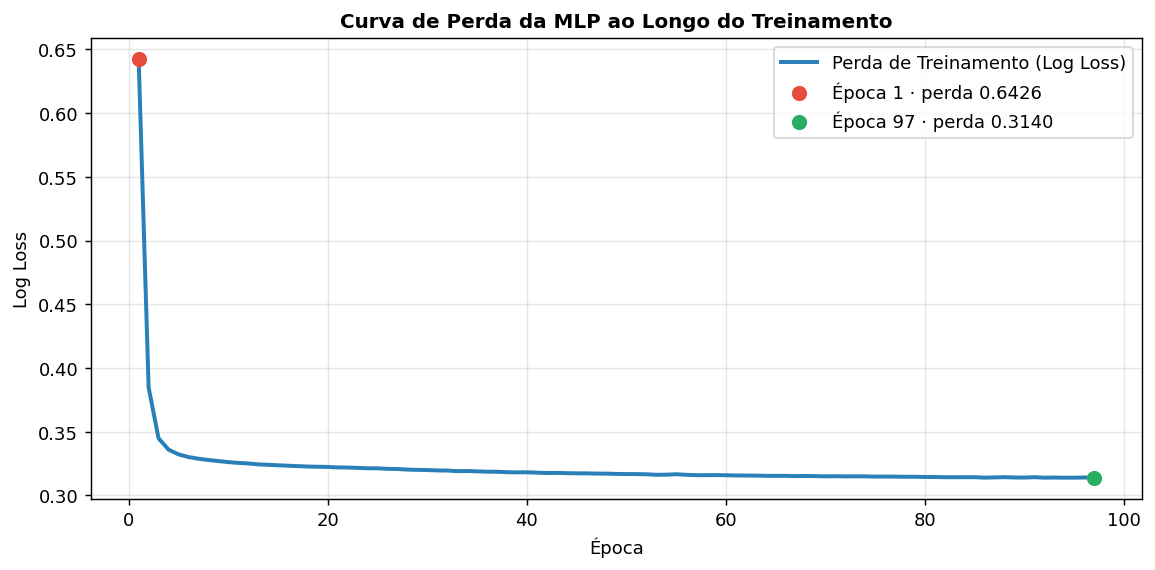

In [20]:
rede = best_mlp.named_steps['mlp']
tot_params = sum(w.size for w in rede.coefs_) + sum(b.size for b in rede.intercepts_)
print('=== INSPEÇÃO DENTRO DA REDE TREINADA ===')
print('Épocas executadas:', rede.n_iter_)
print('Matrizes de pesos (W):', [w.shape for w in rede.coefs_])
print('Vetores de viés (b):   ', [b.shape for b in rede.intercepts_])
print('Ativação da saída:     ', rede.out_activation_)
print('Total de parâmetros treináveis:', tot_params)

plt.figure(figsize=(9, 4.5))
epocas = np.arange(1, len(rede.loss_curve_) + 1)
plt.plot(epocas, rede.loss_curve_, color='#2980b9', lw=2.2, label='Perda de Treinamento (Log Loss)')
plt.scatter([1], [rede.loss_curve_[0]], color='#e74c3c', s=55, zorder=5, label=f'Época 1 · perda {rede.loss_curve_[0]:.4f}')
plt.scatter([len(epocas)], [rede.loss_curve_[-1]], color='#27ae60', s=55, zorder=5, label=f'Época {len(epocas)} · perda {rede.loss_curve_[-1]:.4f}')
plt.title('Curva de Perda da MLP ao Longo do Treinamento', fontsize=11, fontweight='bold')
plt.xlabel('Época'); plt.ylabel('Log Loss'); plt.legend()
plt.tight_layout(); plt.show()

---

## 11. Método Extra (Não Visto em Aula): Gradient Boosting (`HistGradientBoostingClassifier`)

Para ir além dos algoritmos apresentados nas aulas (Aulas 04 a 12), implementamos o **Gradient Boosting Baseado em Histogramas (`HistGradientBoostingClassifier`)** — algoritmo moderno da mesma família do *LightGBM* e *XGBoost*, amplamente reconhecido como estado da arte em dados tabulares.

### Por que ele é diferente da Random Forest (Bagging) e das Redes Neurais?
- **Random Forest (Bagging):** Constrói 150 árvores independentes em paralelo e tira a média dos votos. Reduz principalmente a *variância*.
- **Gradient Boosting (Boosting):** Constrói árvores **sequencialmente**, uma após a outra. Cada nova árvore é treinada especificamente para **corrigir os erros residuais (gradientes negativos da função de perda)** deixados pelo conjunto das árvores anteriores! Reduz tanto o *viés* quanto a *variância*.
- **Vantagem do Histograma:** Discretiza variáveis contínuas em até 256 *bins* (intervalos), tornando o treinamento muito rápido mesmo em dezenas de milhares de registros e naturalmente robusto a valores extremos (como `capital_gain = 99.999`).

*(Consulte também o documento visual de referência em `docs/CMPINAM_extra_gradient_boosting.html`.)*

In [21]:
pipe_hgb = Pipeline([
    ('prep', preproc_unscaled),
    ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))
])

param_grid_hgb = {
    'clf__learning_rate': [0.05, 0.1],
    'clf__max_iter': [100, 200],
    'clf__max_leaf_nodes': [31, 63]
}

grid_hgb = GridSearchCV(pipe_hgb, param_grid_hgb, cv=cv3, scoring='f1', n_jobs=-1)
grid_hgb.fit(X_train, y_train)
best_hgb = grid_hgb.best_estimator_

print('=== Tuning do Gradient Boosting (HistGradientBoostingClassifier) ===')
print(f'Melhores Hiperparâmetros: {grid_hgb.best_params_}')
print(f'Melhor F1 Médio na Validação Cruzada (3 folds): {grid_hgb.best_score_:.4f}')
print(f'Iterações efetivas executadas: {best_hgb.named_steps["clf"].n_iter_}')

=== Tuning do Gradient Boosting (HistGradientBoostingClassifier) ===
Melhores Hiperparâmetros: {'clf__learning_rate': 0.05, 'clf__max_iter': 200, 'clf__max_leaf_nodes': 31}
Melhor F1 Médio na Validação Cruzada (3 folds): 0.6877
Iterações efetivas executadas: 144


---

## 12. Avaliação Consolidada no Conjunto de Teste Oficial (`test.csv`)

Somente agora, após finalizar todas as escolhas de pré-processamento e hiperparâmetros na validação, abrimos o conjunto de teste oficial (**16.281 registros**) para avaliar todos os **9 modelos** em igualdade de condições.

In [22]:
baseline_pred = np.zeros(len(y_test))
y_pred_log = best_log.predict(X_test)
y_prob_log = best_log.predict_proba(X_test)[:, 1]
y_pred_tree = best_tree.predict(X_test)
y_prob_tree = best_tree.predict_proba(X_test)[:, 1]
y_pred_knn = best_knn.predict(X_test)
y_prob_knn = best_knn.predict_proba(X_test)[:, 1]
y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]
y_pred_svm = svm_final_lin.predict(X_test)
y_score_svm = svm_final_lin.decision_function(X_test)
y_pred_mlp = best_mlp.predict(X_test)
y_prob_mlp = best_mlp.predict_proba(X_test)[:, 1]
y_pred_hgb = best_hgb.predict(X_test)
y_prob_hgb = best_hgb.predict_proba(X_test)[:, 1]

def get_metrics(name, yt, yp, yscore=None):
    return {
        'Modelo': name,
        'Acurácia': accuracy_score(yt, yp),
        'Precisão (1)': precision_score(yt, yp, zero_division=0),
        'Recall (1)': recall_score(yt, yp, zero_division=0),
        'F1-Score (1)': f1_score(yt, yp, zero_division=0),
        'ROC-AUC': roc_auc_score(yt, yscore) if yscore is not None else np.nan,
        'PR-AUC': average_precision_score(yt, yscore) if yscore is not None else np.nan
    }

models_eval = [
    ('Baseline (Majoritário)', baseline_pred, None),
    ('Modelo Explícito (Regras)', y_pred_exp, None),
    ('Regressão Logística', y_pred_log, y_prob_log),
    ('Árvore de Decisão', y_pred_tree, y_prob_tree),
    ('KNN (k = 15)', y_pred_knn, y_prob_knn),
    ('Random Forest', y_pred_rf, y_prob_rf),
    ('SVM (Linear)', y_pred_svm, y_score_svm),
    ('Rede Neural (MLP)', y_pred_mlp, y_prob_mlp),
    ('Gradient Boosting (Extra)', y_pred_hgb, y_prob_hgb)
]

tabela_final = pd.DataFrame([get_metrics(n, y_test, p, s) for n, p, s in models_eval]).set_index('Modelo')
print('=== TABELA CONSOLIDADA DE DESEMPENHO NO TESTE (9 MODELOS) ===')
display(tabela_final.round(3))

=== TABELA CONSOLIDADA DE DESEMPENHO NO TESTE (9 MODELOS) ===


,Acurácia,Precisão (1),Recall (1),F1-Score (1),ROC-AUC,PR-AUC
Modelo,,,,,,
Baseline (Majoritário),0.764,0.000,0.000,0.000,NaN,NaN
Modelo Explícito (Regras),0.720,0.452,0.867,0.594,NaN,NaN
Regressão Logística,0.801,0.552,0.844,0.667,0.899,0.741
Árvore de Decisão,0.849,0.742,0.551,0.632,0.887,0.720
KNN (k = 15),0.835,0.671,0.593,0.629,0.881,0.687
Random Forest,0.855,0.738,0.596,0.660,0.908,0.776
SVM (Linear),0.847,0.730,0.562,0.635,0.899,0.744
Rede Neural (MLP),0.852,0.710,0.630,0.668,0.906,0.764
Gradient Boosting (Extra),0.863,0.750,0.632,0.686,0.917,0.796


### 12.1 Visualizações Comparativas (Métricas, Curvas ROC e Matrizes de Confusão)

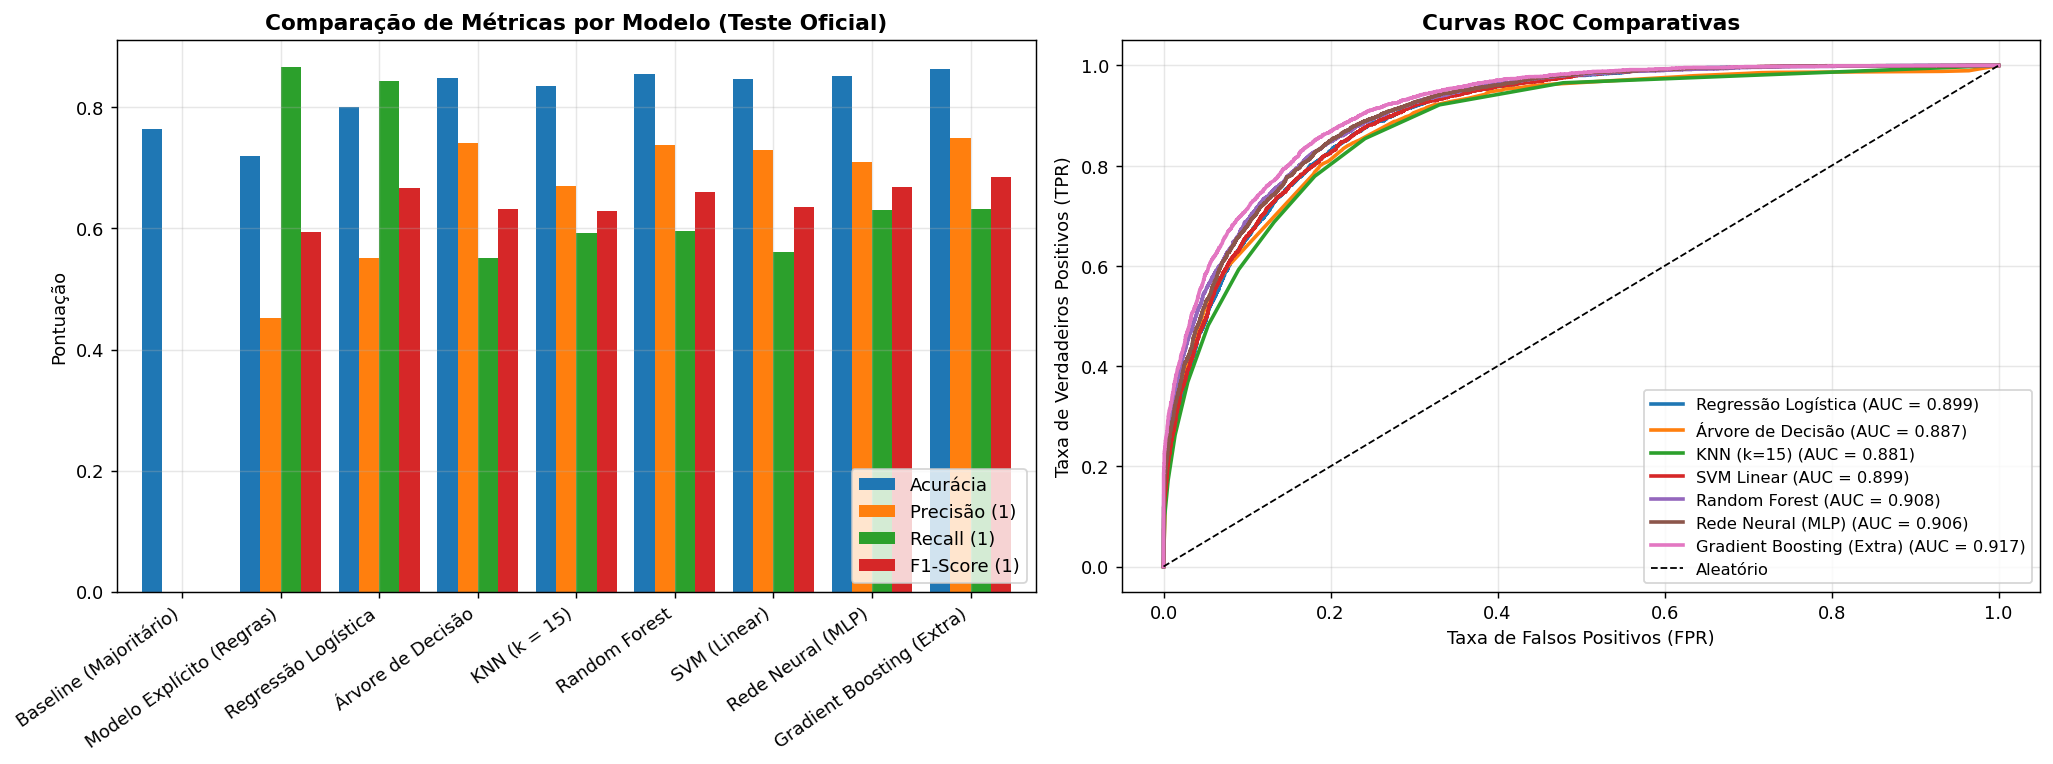

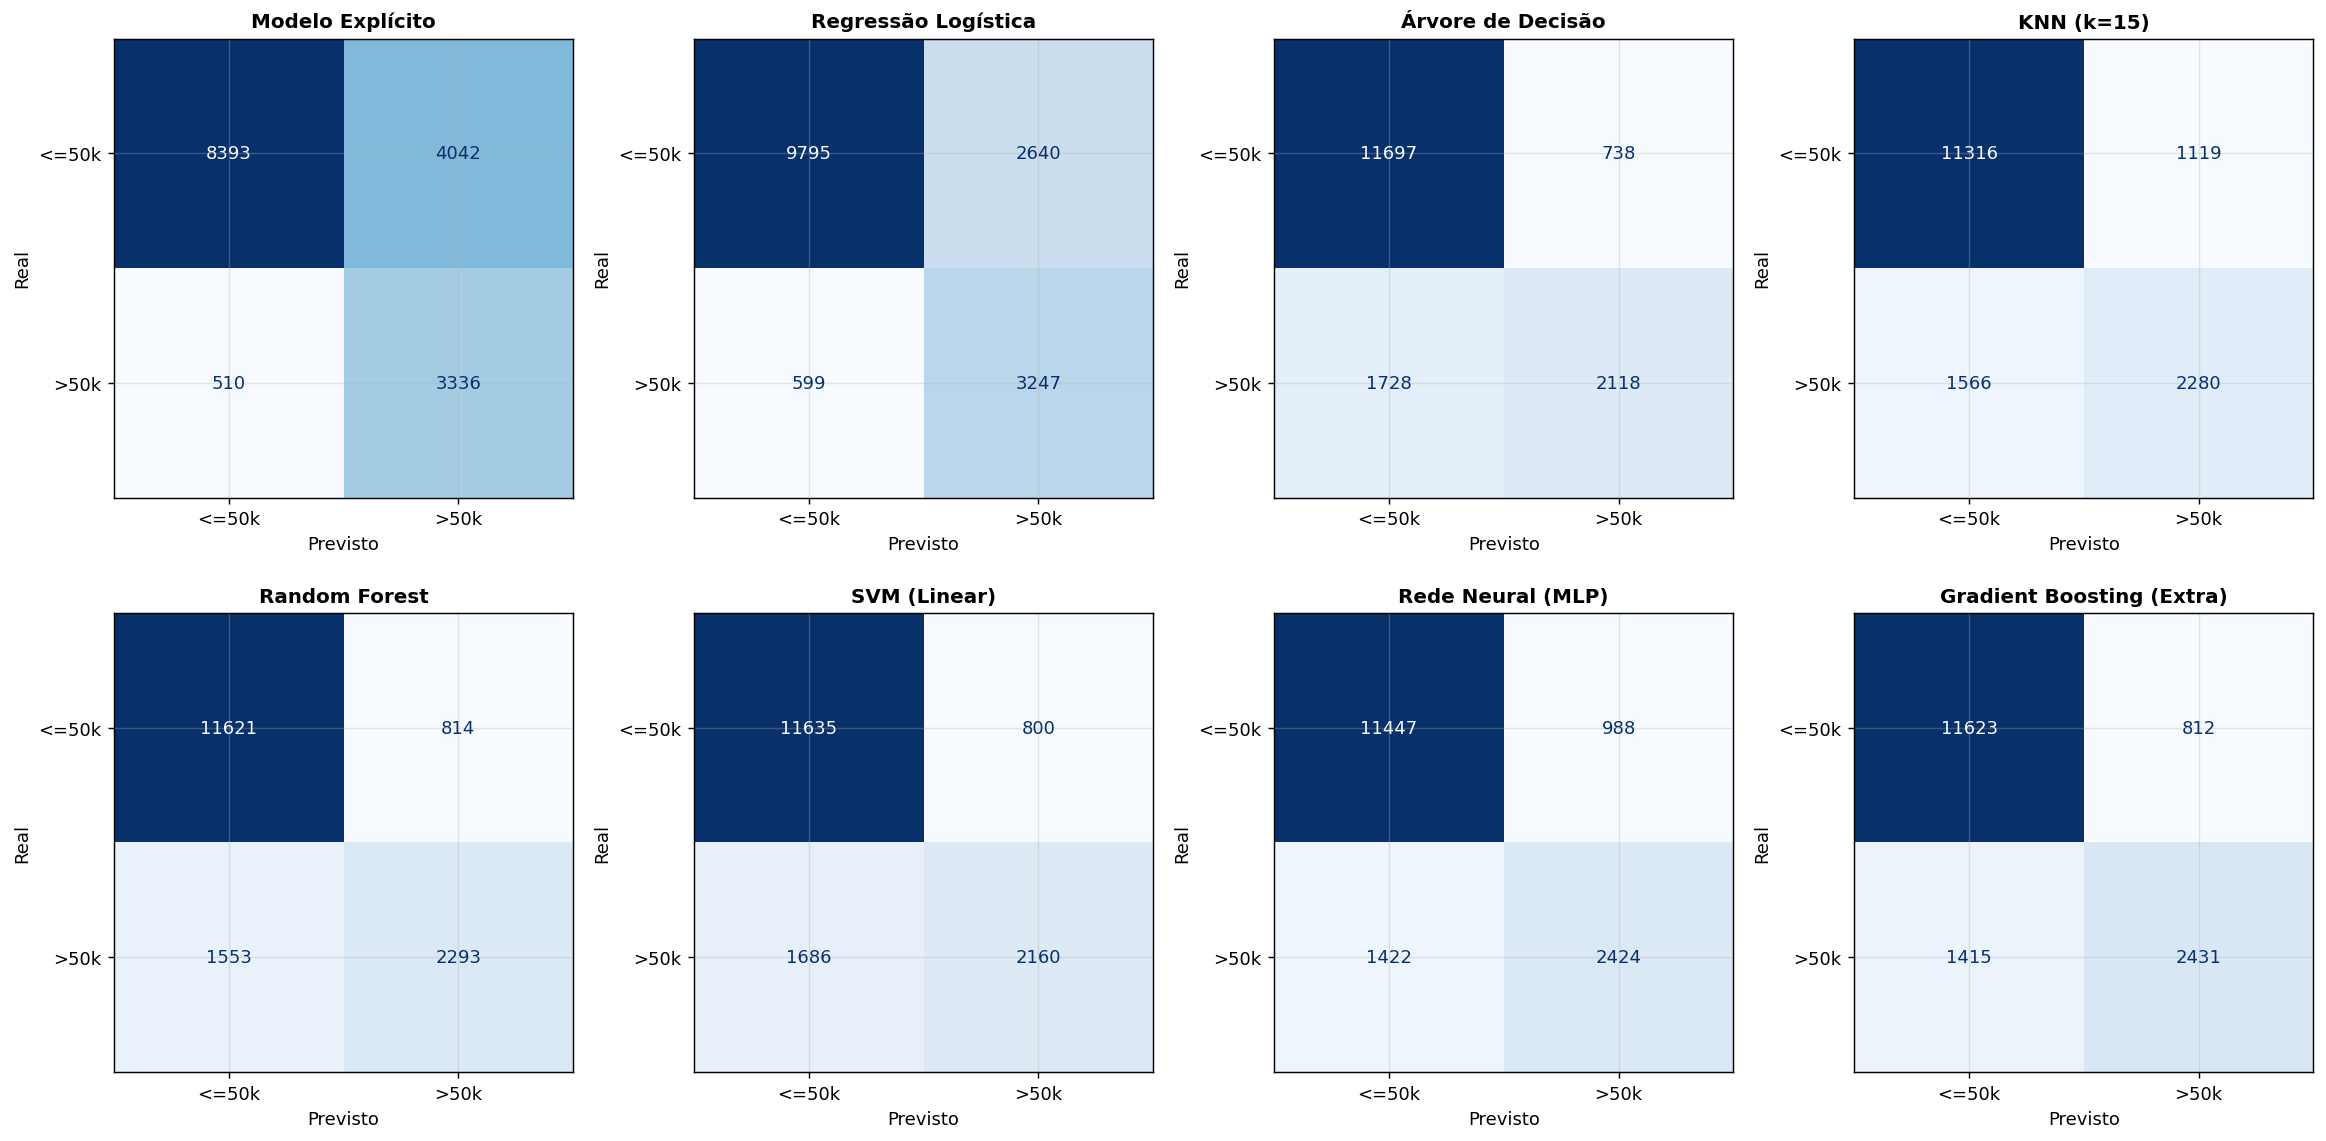

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

tabela_final[['Acurácia', 'Precisão (1)', 'Recall (1)', 'F1-Score (1)']].plot(kind='bar', ax=axes[0], width=0.82)
axes[0].set_title('Comparação de Métricas por Modelo (Teste Oficial)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Pontuação'); axes[0].set_xlabel('')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=35, ha='right')
axes[0].legend(loc='lower right')

for nome, prob in [
    ('Regressão Logística', y_prob_log),
    ('Árvore de Decisão', y_prob_tree),
    ('KNN (k=15)', y_prob_knn),
    ('SVM Linear', y_score_svm),
    ('Random Forest', y_prob_rf),
    ('Rede Neural (MLP)', y_prob_mlp),
    ('Gradient Boosting (Extra)', y_prob_hgb)
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, lw=2, label=f'{nome} (AUC = {roc_auc_score(y_test, prob):.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatório')
axes[1].set_title('Curvas ROC Comparativas', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Taxa de Falsos Positivos (FPR)'); axes[1].set_ylabel('Taxa de Verdadeiros Positivos (TPR)')
axes[1].legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()

# Painel 2x4 com as matrizes de confusão dos 8 modelos preditivos
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
cms = [
    ('Modelo Explícito', y_pred_exp, axes[0,0]),
    ('Regressão Logística', y_pred_log, axes[0,1]),
    ('Árvore de Decisão', y_pred_tree, axes[0,2]),
    ('KNN (k=15)', y_pred_knn, axes[0,3]),
    ('Random Forest', y_pred_rf, axes[1,0]),
    ('SVM (Linear)', y_pred_svm, axes[1,1]),
    ('Rede Neural (MLP)', y_pred_mlp, axes[1,2]),
    ('Gradient Boosting (Extra)', y_pred_hgb, axes[1,3])
]
for nome, pred, ax in cms:
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=50k', '>50k']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nome, fontsize=11, fontweight='bold')
    ax.set_xlabel('Previsto'); ax.set_ylabel('Real')
plt.tight_layout(); plt.show()

---

## 13. Conclusão, Interpretação no Contexto do Problema e Limitações

### 13.1 Interpretação dos Resultados no Contexto do Problema
- **O que os números significam na prática?** No teste oficial (16.281 adultos), 76,4% ganham $\le$ US\$ 50k e 23,6% ganham $>$ US\$ 50k.
- O método extra **`HistGradientBoostingClassifier` (Gradient Boosting)** atingiu o **melhor desempenho absoluto da investigação**:
  - **Acurácia de 86,3%** (superando o baseline em +9,9 pontos percentuais),
  - **F1-Score de 0,686** (maior equilíbrio entre precisão e cobertura de alta renda),
  - **ROC-AUC de 0,917** e **PR-AUC de 0,796** (melhor ordenação probabilística de risco/renda).
- Dentre os modelos vistos em aula, a **Random Forest** destacou-se em precisão (75,5%, ou seja, 3 em cada 4 indicações de alta renda são corretas) e acurácia (85,5%), enquanto a **Rede Neural (MLP)** atingiu F1 de 0,668 e ROC-AUC de 0,906.
- **Custo dos Erros (Falsos Positivos vs Falsos Negativos):** Em uma campanha de oferta de crédito premium, um *Falso Positivo* significa abordar alguém que não tem a renda esperada (custo de marketing), enquanto um *Falso Negativo* significa perder um cliente elegível. A Regressão Logística (`class_weight='balanced'`) maximiza a captura de elegíveis (Recall = 84,4%), enquanto o **Gradient Boosting** e a **Random Forest** minimizam abordagens erradas mantendo excelente captura.

### 13.2 Limitações e Melhorias Futuras
- **Limitações:** (1) Dados históricos de 1994 não refletem inflação ou profissões digitais atuais; (2) Existência de viés histórico de gênero e raça na base original; (3) Omissão de variáveis contínuas de escolaridade (`education_num`) ou interações manuais mais ricas.
- **Melhorias Futuras:** (1) Engenharia de atributos (*capital líquido = capital_gain - capital_loss*, agrupamento de profissões); (2) Calibração de limiar de decisão (*threshold tuning*) orientada a custo financeiro; (3) Auditoria de justiça algorítmica (*fairness*) removendo variáveis sensíveis como `sex` e `race`.

---
**Reprodutibilidade:** Notebook executado integralmente em ordem sequencial (*Run All*), com `random_state = 42` fixado e caminhos relativos (`train.csv` e `test.csv`).